> **Executed record of a Kaggle kernel.** The cells below are the cells that ran. Kaggle does not return the executed notebook, so the outputs were put back afterwards by `tools/attach_kaggle_outputs.py`: printed text comes from the kernel's log (each line assigned to the cell whose code prints it), and each table or figure comes from the CSV or PNG file that cell saved. Everything shown was produced by the run; the placement is a reconstruction. Kernel: `dr-s8-train`.

> **Kaggle kernel `dr-s8-train`.** The 10 training runs (cheap recipe x 3 seeds, stacked recipe x 3 seeds, 4 leave-one-out) and the analysis. Built by `experiments/10_stacked_recipe/kaggle/build_kernels.py` from `experiments/10_stacked_recipe/10_stacked_recipe.ipynb`; only the Drive setup and the QUICK_TEST switch differ.

# Stage 8: Stacking the Proven Training Levers on Soft Labels
### Do the Stage 4b recipe levers add up on a single soft-label EfficientNet-B3?

**Hypothesis (M3, written before this notebook was run):** [`experiments/10_stacked_recipe/hypothesis.md`](hypothesis.md). Peak lr 3e-4, strong augmentation, Ben Graham pre-processing and removal of contradictory duplicate labels (each helped in Stage 4b when tested alone) are combined with Stage 5's Gaussian soft labels (sigma 0.5), inside the 20-epoch recipe with warm-up, cosine decay, an EMA of the weights and 8-view test-time augmentation. A **single** model (no snapshot ensemble).

| Run | Recipe | Seeds |
|---|---|---|
| `R0_s*` | cheap recipe only (20 epochs, EMA, lr 1e-4, CLAHE, base augmentation) | 42, 43, 44 |
| `FULL_s*` | R0 + lr 3e-4 + strong augmentation + Ben Graham + label cleaning | 42, 43, 44 |
| `minus_lr / aug / graham / clean _s42` | FULL with one lever removed | 42 |

Arms: **G** = arg-max, **H** = expected grade with cut-offs tuned on the validation set only. Baselines (not retrained): the Stage 5 soft-label runs (`dr-s5-train` kernel output) and the paper-style cross-entropy control `ce_s42_k` from the project repository.

Set `QUICK_TEST = True` in section 1 first to check the whole pipeline in a few minutes.

## 1. Setup and settings

In [1]:
import hashlib
import copy
import io
import json
import math
import os
import random
import subprocess
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, fields, replace
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, train_test_split
from tqdm.auto import tqdm

try:
    import timm
except ImportError:                      # not preinstalled on this machine
    !pip install -q timm
    import timm

CLASS_NAMES = ["No DR", "Mild", "Moderate", "Severe", "PDR"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Kaggle: results go to /kaggle/working (this kernel's output); images are downloaded to the local disk.
WORK_DIR = Path("/kaggle/working/dr-grading")
LOCAL_DIR = Path("/tmp/dr")
LOCAL_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU found (very slow!)")

device: cuda | Tesla T4


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


In [2]:
QUICK_TEST = False        # True = tiny run (2 epochs, a few batches, small images, separate folder) to check the pipeline
CHECKPOINT_EVERY = 1      # save a resumable checkpoint every N epochs
SAVE_WEIGHTS = False      # final EMA weights are not needed afterwards
SPLIT_SEED = 42           # the train/val/test split is the same as in Stages 3 to 7


@dataclass
class Config:
    # R0 = Stage 4b's cheap recipe (EfficientNet-B3, paper head, CLAHE, 300 px, Adam lr 1e-4, weight decay 1e-4,
    # batch 16, grad clip 0.1, 20 epochs with 1 warm-up epoch, cosine decay and an EMA of the weights), trained with
    # Stage 5's Gaussian soft labels instead of MSE regression.
    backbone: str = "efficientnet_b3"
    image_size: int = 300
    preproc: str = "clahe"        # "clahe" (paper) or "graham" (Ben Graham: subtract the local average colour)
    aug: str = "base"             # "base" = flip + rotation; "strong" = + zoom, shift, brightness, gamma
    epochs: int = 20
    warmup_epochs: int = 1
    batch_size: int = 16
    lr: float = 1e-4              # peak learning rate
    weight_decay: float = 1e-4
    grad_clip: float = 0.1
    ema_decay: float = 0.998
    sigma: float = 0.5            # width of the Gaussian soft label, in grades
    clean_labels: bool = False    # drop images whose identical copies carry different grades from training
    seed: int = 42
    pretrained: bool = True
    use_amp: bool = True
    max_train_batches: int = 0    # 0 = all batches; >0 only for the quick test


BASE_CFG = Config()
SEEDS = [42, 43, 44]
FULL_LEVERS = dict(lr=3e-4, aug="strong", preproc="graham", clean_labels=True)
LEVER_KEYS = {"lr": ["lr"], "aug": ["aug"], "graham": ["preproc"], "clean": ["clean_labels"]}

STAGE8_DIR = WORK_DIR / "stage8"
if QUICK_TEST:
    BASE_CFG = replace(BASE_CFG, epochs=2, max_train_batches=3, image_size=96)
    SEEDS = [42, 43]
    STAGE8_DIR = WORK_DIR / "stage8_quick_test"                 # never mixed with the real runs
if device.type != "cuda" and not QUICK_TEST:
    raise RuntimeError("Training needs a GPU: enable a T4 for this kernel.")
if device.type != "cuda":
    BASE_CFG = replace(BASE_CFG, use_amp=False)
RUNS_DIR, FIG_DIR = STAGE8_DIR / "runs", STAGE8_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

EXPERIMENTS = {}
for seed in SEEDS:
    EXPERIMENTS[f"R0_s{seed}"] = replace(BASE_CFG, seed=seed)
    EXPERIMENTS[f"FULL_s{seed}"] = replace(BASE_CFG, seed=seed, **FULL_LEVERS)
for lever, keys in LEVER_KEYS.items():                          # leave-one-out, seed 42
    EXPERIMENTS[f"minus_{lever}_s{SEEDS[0]}"] = replace(BASE_CFG, seed=SEEDS[0], **{k: v for k, v in FULL_LEVERS.items() if k not in keys})
# CLAHE runs first, then the Ben Graham runs, so the pre-processed images are rebuilt only once.
ORDER = sorted(EXPERIMENTS, key=lambda n: EXPERIMENTS[n].preproc != "clahe")
print(json.dumps(asdict(BASE_CFG), indent=2))
print("full recipe:", FULL_LEVERS)
print("run order:", ", ".join(ORDER))

{
  "backbone": "efficientnet_b3",
  "image_size": 300,
  "preproc": "clahe",
  "aug": "base",
  "epochs": 20,
  "warmup_epochs": 1,
  "batch_size": 16,
  "lr": 0.0001,
  "weight_decay": 0.0001,
  "grad_clip": 0.1,
  "ema_decay": 0.998,
  "sigma": 0.5,
  "clean_labels": false,
  "seed": 42,
  "pretrained": true,
  "use_amp": true,
  "max_train_batches": 0
}
full recipe: {'lr': 0.0003, 'aug': 'strong', 'preproc': 'graham', 'clean_labels': True}
run order: R0_s42, R0_s43, R0_s44, minus_graham_s42, FULL_s42, FULL_s43, FULL_s44, minus_lr_s42, minus_aug_s42, minus_clean_s42


## 2. Data and split

Same source, cache and split as Stages 3 and 4 (stratified 70/15/15, seed 42). Block 3 trains on train + validation (3,112 images) in 5 folds that keep identical images together, so out-of-fold predictions are never made on a copy of a training image.

In [3]:
HF_REPO = "sngsfydy/aptos"
IMG_DIR = LOCAL_DIR / "aptos512"
DRIVE_CACHE = WORK_DIR / "aptos512.zip"
MAX_SIDE = 512


def list_shards():
    with urllib.request.urlopen(f"https://huggingface.co/api/datasets/{HF_REPO}/tree/main/data") as r:
        return sorted(f["path"] for f in json.load(r) if f["path"].endswith(".parquet"))


def convert_shard(parquet_path, out_dir):
    # Save every image in one parquet shard as a <hash>.jpg (<= 512 px). Returns [(file name, grade), ...].
    rows = []
    pf = pq.ParquetFile(parquet_path)
    for group in range(pf.num_row_groups):
        table = pf.read_row_group(group).to_pydict()
        for img, label in zip(table["image"], table["label"]):
            raw = img["bytes"]
            name = hashlib.sha1(raw).hexdigest()[:16] + ".jpg"     # identical photos get identical names
            im = Image.open(io.BytesIO(raw)).convert("RGB")
            scale = MAX_SIDE / max(im.size)
            im.resize((round(im.width * scale), round(im.height * scale)), Image.LANCZOS).save(out_dir / name, quality=95)
            rows.append((name, int(label)))
    return rows


def download_aptos(out_dir):
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []
    for shard in list_shards():
        local = LOCAL_DIR / Path(shard).name
        print("downloading", local.name, flush=True)
        subprocess.run(["curl", "-sSL", "--retry", "5", "-o", str(local),
                        f"https://huggingface.co/datasets/{HF_REPO}/resolve/main/{shard}"], check=True)
        rows += convert_shard(local, out_dir)
        local.unlink()                                             # free the disk before the next shard
        print(f"  {len(rows)} images so far", flush=True)
    pd.DataFrame(rows, columns=["id_code", "label"]).to_csv(out_dir / "labels.csv", index=False)


if not (IMG_DIR / "labels.csv").exists():
    if DRIVE_CACHE.exists():                                       # Stage 3 (or an earlier session) did the download
        print("restoring cached images from Drive ...")
        subprocess.run(["unzip", "-q", "-o", str(DRIVE_CACHE), "-d", str(IMG_DIR)], check=True)
    else:
        download_aptos(IMG_DIR)
        print("saving a cache to Drive for next time ...")
        pass

df = pd.read_csv(IMG_DIR / "labels.csv")
df["path"] = df["id_code"].map(lambda name: IMG_DIR / name)
labels = df["label"].to_numpy()
print(f"{len(df)} images, {df['id_code'].nunique()} distinct files")

downloading train-00000-of-00013-b6971806b485b32b.parquet
  282 images so far
downloading train-00001-of-00013-3ef9284bda48b8de.parquet
  564 images so far
downloading train-00002-of-00013-3007d5f3a80d01a9.parquet
  846 images so far
downloading train-00003-of-00013-719dc2a41d6066fd.parquet
  1128 images so far
downloading train-00004-of-00013-1f950a0df3320b4b.parquet
  1410 images so far
downloading train-00005-of-00013-c0ede249a4a1709b.parquet
  1692 images so far
downloading train-00006-of-00013-da6bef6a92e83c30.parquet
  1974 images so far
downloading train-00007-of-00013-4f07a72750e770a9.parquet
  2256 images so far
downloading train-00008-of-00013-f29fe432adc405e3.parquet
  2538 images so far
downloading train-00009-of-00013-8df8c03a53f6153a.parquet
  2819 images so far
downloading train-00010-of-00013-5ce8efdfff11f693.parquet
  3100 images so far
downloading train-00011-of-00013-dc0bde52a2716ecc.parquet
  3381 images so far
downloading train-00012-of-00013-2fde0e05e0019c87.parqu

In [4]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


with ThreadPoolExecutor(os.cpu_count()) as pool:
    df["hash"] = list(tqdm(pool.map(file_hash, df["path"]), total=len(df), desc="hashing"))
hashes = df["hash"].to_numpy()
groups = df.groupby("hash")["label"].agg(["size", "nunique"])
CONFLICT = df["hash"].isin(set(groups.index[groups["nunique"] > 1])).to_numpy()


def make_split(positions, seed=SPLIT_SEED, val_frac=0.15, test_frac=0.15):
    # Stratified train/val/test row positions. With all positions this is exactly the Stage 3 / Stage 4 split.
    train_val, test = train_test_split(positions, test_size=test_frac, stratify=labels[positions], random_state=seed)
    train, val = train_test_split(train_val, test_size=val_frac / (1 - test_frac),
                                  stratify=labels[train_val], random_state=seed)
    return {"train": np.sort(train), "val": np.sort(val), "test": np.sort(test)}


SPLIT = make_split(np.arange(len(df)))
TRAINVAL = np.sort(np.concatenate([SPLIT["train"], SPLIT["val"]]))
TEST, Y_TEST = SPLIT["test"], labels[SPLIT["test"]]
# Test images with an identical copy in the training data (train for Blocks 1-2, train + val for Block 3).
TEST_TWIN = np.isin(hashes[TEST], hashes[TRAINVAL])
print(f"train {len(SPLIT['train'])}, val {len(SPLIT['val'])}, test {len(TEST)}; "
      f"{CONFLICT.sum()} images with conflicting duplicate grades; "
      f"{TEST_TWIN.sum()} test images have a twin in train + val")

train 2562, val 550, test 550; 62 images with conflicting duplicate grades; 36 test images have a twin in train + val


## 3. Metrics and decision rules

Same QWK, cut-off search and metrics as Stage 4. New: **cross-fitted QWK**, the screening metric. The cut-offs are tuned on 4/5 of the held-out images and applied to the other 1/5, in turn, so no image is graded by cut-offs that were tuned on it.

In [ ]:
ROUNDING = np.array([0.5, 1.5, 2.5, 3.5])


def qwk(y, pred, k=NUM_CLASSES):
    # Quadratic weighted kappa from the confusion matrix (same value as sklearn's cohen_kappa_score, much faster).
    cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k).astype(float)
    weights = np.subtract.outer(np.arange(k), np.arange(k)) ** 2 / (k - 1) ** 2
    expected = np.outer(cm.sum(1), cm.sum(0)) / cm.sum()
    denom = (weights * expected).sum()
    return float(1 - (weights * cm).sum() / denom) if denom > 0 else 0.0


def apply_cutoffs(score, cutoffs):
    return np.digitize(score, cutoffs).astype(int)


def fit_cutoffs(score, y, step=0.01, passes=3):
    # Coordinate search: move one cut-off at a time to the grid value with the best QWK, keeping them ordered.
    cutoffs = ROUNDING.copy()
    best = qwk(y, apply_cutoffs(score, cutoffs))
    for _ in range(passes):
        for i in range(len(cutoffs)):
            lo = cutoffs[i - 1] + step if i > 0 else -0.5
            hi = cutoffs[i + 1] - step if i < len(cutoffs) - 1 else NUM_CLASSES - 0.5
            for value in np.arange(lo, hi + 1e-9, step):
                trial = cutoffs.copy()
                trial[i] = value
                score_trial = qwk(y, apply_cutoffs(score, trial))
                if score_trial > best:                       # strictly better: ties keep the current cut-off
                    best, cutoffs = score_trial, trial
    return cutoffs


def crossfit_qwk(score, y, k=5, seed=0):
    # QWK with tuned cut-offs, but every image is graded by cut-offs tuned on the other images.
    pred = np.empty_like(y)
    for fit, held in StratifiedKFold(k, shuffle=True, random_state=seed).split(score, y):
        pred[held] = apply_cutoffs(score[held], fit_cutoffs(score[fit], y[fit]))
    return qwk(y, pred)


def majority_vote(snapshot_probs):
    # Stage 4 arm A: (n_snapshots, n_images, 5) -> one grade per image (the paper's ensemble rule).
    votes = snapshot_probs.argmax(-1)
    tally = np.stack([(votes == c).sum(0) for c in range(NUM_CLASSES)], 1).astype(float)
    return (tally + 1e-3 * snapshot_probs.mean(0)).argmax(1)


def safe_auc(y_binary, score):
    return float(roc_auc_score(y_binary, score)) if 0 < y_binary.sum() < len(y_binary) else float("nan")


def compute_metrics(y, pred, ref_score):
    # ref_score: any score that ranks "referable DR" (grade >= 2); the regression output itself for our models.
    _, rec, _, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    ref_true, ref_pred = y >= 2, pred >= 2
    return {
        "qwk": qwk(y, pred),
        "accuracy": float(accuracy_score(y, pred)),
        "macro_f1": float(f1_score(y, pred, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        **{f"recall_{name}": float(rec[c]) for c, name in enumerate(CLASS_NAMES)},
        "off_by_2_or_more": int(np.sum(np.abs(y - pred) >= 2)),
        "ref_sensitivity": float((ref_pred & ref_true).sum() / max(ref_true.sum(), 1)),
        "ref_specificity": float((~ref_pred & ~ref_true).sum() / max((~ref_true).sum(), 1)),
        "ref_auc": safe_auc(ref_true, ref_score),
    }


def bootstrap_qwk(y, pred_a, pred_b=None, n_boot=2000, seed=0):
    # 95% interval of QWK(pred_a), or of QWK(pred_b) - QWK(pred_a) on the same resampled images.
    rng = np.random.default_rng(seed)
    values = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        values[i] = qwk(y[idx], pred_a[idx]) if pred_b is None else qwk(y[idx], pred_b[idx]) - qwk(y[idx], pred_a[idx])
    return np.percentile(values, [2.5, 97.5])

## 5. Pre-processing

* **`clahe`** (paper, Stages 3-4): CLAHE on the LAB lightness channel, 5x5 Gaussian blur, square resize.
* **`graham`** (Ben Graham, Kaggle 2015 winner): resize, then subtract a large Gaussian blur (`4*img - 4*blur + 128`), which removes lighting and camera colour differences and keeps local detail. The black background is restored, with the bright rim at its edge trimmed.

One pre-processed copy of all images is kept in memory and rebuilt only when a run needs another size or method.

In [ ]:
def load_shrunk(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    h, w = bgr.shape[:2]
    if max(h, w) > 512:
        scale = 512 / max(h, w)
        bgr = cv2.resize(bgr, (round(w * scale), round(h * scale)), interpolation=cv2.INTER_AREA)
    return bgr


def preprocess(path, size, method):
    # Returns RGB uint8 (size, size, 3).
    bgr = load_shrunk(path)
    if method == "clahe":
        lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
        lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
        bgr = cv2.GaussianBlur(cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), (5, 5), 0)
        bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
    elif method == "graham":
        bgr = cv2.resize(bgr, (size, size), interpolation=cv2.INTER_AREA)
        retina = (cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY) > 10).astype(np.uint8)
        retina = cv2.erode(retina, np.ones((max(3, size // 50),) * 2, np.uint8)).astype(bool)
        bgr = cv2.addWeighted(bgr, 4, cv2.GaussianBlur(bgr, (0, 0), size / 30), -4, 128)
        bgr[~retina] = 0
    else:
        raise ValueError(f"unknown pre-processing {method!r}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


images, _images_key = None, None


def ensure_images(cfg):
    # Make the global `images` hold every image pre-processed as this run needs.
    global images, _images_key
    key = (cfg.preproc, cfg.image_size)
    if key == _images_key:
        return
    images = None                                                    # free the old copy first
    paths, out = df["path"].tolist(), np.empty((len(df), cfg.image_size, cfg.image_size, 3), dtype=np.uint8)

    def fill(i):
        out[i] = preprocess(paths[i], cfg.image_size, cfg.preproc)

    t0 = time.time()
    with ThreadPoolExecutor(os.cpu_count()) as pool:
        list(tqdm(pool.map(fill, range(len(paths))), total=len(paths), desc=f"pre-processing {key}", leave=False))
    images, _images_key = out, key
    print(f"  images: {cfg.preproc}, {cfg.image_size} px, {out.nbytes / 1e9:.2f} GB, {time.time() - t0:.0f}s")

## 6. Model and augmentation

Any timm backbone with the paper's head ending in **one output** (the Stage 4 ordinal model). Inputs are normalised with each backbone's own pre-training statistics (the ImageNet-21k EfficientNetV2 expects 0.5/0.5).

**Augmentation** (on the GPU): `base` = random flip + rotation (Stage 3). `strong` adds zoom 0.9-1.15x, a shift of up to 5%, brightness x0.8-1.2 and gamma 0.8-1.25; all of them keep the black background black. **TTA** averages 8 exact views: 4 rotations by 90 degrees, with and without a flip.

In [ ]:
class DRNet(nn.Module):
    def __init__(self, backbone, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0, global_pool="avg")
        self.head = nn.Sequential(
            nn.Linear(self.backbone.num_features, 512), nn.Dropout(0.5), nn.ReLU(inplace=True),
            nn.Linear(512, 512), nn.Dropout(0.25), nn.ReLU(inplace=True),
            nn.Linear(512, NUM_CLASSES),
        )

    def forward(self, x):
        return self.head(self.backbone(x))


NORM = {}


def set_norm(model):
    # Use the backbone's own pre-training mean/std for every input from now on.
    cfg = model.backbone.pretrained_cfg
    NORM["mean"] = torch.tensor(cfg.get("mean", IMAGENET_MEAN), device=device).view(1, 3, 1, 1)
    NORM["std"] = torch.tensor(cfg.get("std", IMAGENET_STD), device=device).view(1, 3, 1, 1)
    NORM["black"] = -NORM["mean"] / NORM["std"]                     # what a black pixel looks like after normalisation


def to_model_input(batch_uint8):
    # numpy (B, H, W, 3) uint8 -> normalised float tensor (B, 3, H, W) on the GPU.
    x = torch.from_numpy(batch_uint8).to(device).permute(0, 3, 1, 2).float() / 255.0
    return ((x - NORM["mean"]) / NORM["std"]).contiguous(memory_format=torch.channels_last)


def augment_batch(x, strong):
    n = x.shape[0]
    x = x - NORM["black"]                                           # black = 0, so empty corners stay black
    flip = torch.rand(n, device=x.device) < 0.5
    x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
    angle = torch.rand(n, device=x.device) * 2 * math.pi
    zoom = (torch.rand(n, device=x.device) * 0.25 + 0.9) if strong else torch.ones(n, device=x.device)
    shift = ((torch.rand(n, 2, device=x.device) - 0.5) * 0.1) if strong else torch.zeros(n, 2, device=x.device)
    cos, sin = angle.cos() / zoom, angle.sin() / zoom
    theta = torch.stack([torch.stack([cos, -sin, shift[:, 0]], 1), torch.stack([sin, cos, shift[:, 1]], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False) + NORM["black"]
    if strong:                                                      # brightness and gamma in pixel space
        pixels = (x * NORM["std"] + NORM["mean"]).clamp(0, 1)
        gain = torch.rand(n, 1, 1, 1, device=x.device) * 0.4 + 0.8
        gamma = torch.exp((torch.rand(n, 1, 1, 1, device=x.device) - 0.5) * 2 * math.log(1.25))
        x = ((pixels ** gamma * gain).clamp(0, 1) - NORM["mean"]) / NORM["std"]
    return x.contiguous(memory_format=torch.channels_last)


@torch.no_grad()
def predict(model, indices, cfg, tta=False, batch_size=32):
    # Class probabilities (n, 5) per image; with tta, the mean over 4 rotations x {no flip, flip}.
    model.eval()
    out = []
    for start in range(0, len(indices), batch_size):
        x = to_model_input(images[indices[start:start + batch_size]])
        views = [torch.rot90(v, k, dims=(2, 3)).contiguous(memory_format=torch.channels_last)
                 for v in (x, x.flip(-1)) for k in range(4)] if tta else [x]
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            out.append(torch.stack([torch.softmax(model(v).float(), dim=1) for v in views]).mean(0).cpu())
    return torch.cat(out).numpy()

## 7. Training

Stage 4b's loop: **20 epochs**, a 1-epoch warm-up then cosine decay of the learning rate (per step), an **EMA** of the weights (which is what gets evaluated) and, after the last epoch, predictions on the validation and test sets with and without 8-view TTA. The only change from Stage 4b is the loss: the Gaussian soft-label cross-entropy of Stage 5 (five outputs) instead of MSE on one output. A resumable checkpoint is written every epoch, so a stopped run continues.

In [ ]:
GRADES = torch.arange(NUM_CLASSES, device=device).float()


def soft_ce(out, y, sigma):
    # Gaussian soft labels: target mass falls off with the distance from the true grade (Stage 5).
    target = torch.softmax(-(GRADES.view(1, -1) - y.float().view(-1, 1)) ** 2 / (2 * sigma ** 2), dim=1)
    return -(target * F.log_softmax(out, dim=1)).sum(1).mean()


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def lr_factor(step, cfg, steps_per_epoch):
    warm, total = cfg.warmup_epochs * steps_per_epoch, cfg.epochs * steps_per_epoch
    if step < warm:
        return 0.1 + 0.9 * step / warm
    return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))


@torch.no_grad()
def ema_update(ema, model, step, decay):
    d = min(decay, (1 + step) / (10 + step))                        # shorter memory early in training
    for e, m in zip(ema.state_dict().values(), model.state_dict().values()):
        if e.dtype.is_floating_point:
            e.mul_(d).add_(m.detach(), alpha=1 - d)
        else:
            e.copy_(m)


def train_one_epoch(model, ema, optimizer, scaler, cfg, train_idx, rng, step, steps_per_epoch):
    model.train()
    order = rng.permutation(train_idx)
    total_loss, seen = 0.0, 0
    progress = tqdm(range(steps_per_epoch), desc="  training", leave=False)
    for b in progress:
        for group in optimizer.param_groups:
            group["lr"] = cfg.lr * lr_factor(step, cfg, steps_per_epoch)
        idx = np.sort(order[b * cfg.batch_size:(b + 1) * cfg.batch_size])      # sorted = faster memory reads
        x = augment_batch(to_model_input(images[idx]), strong=cfg.aug == "strong")
        y = torch.from_numpy(labels[idx]).to(device).float()
        with torch.autocast(device.type, dtype=torch.float16, enabled=cfg.use_amp):
            out = model(x)
        loss = soft_ce(out.float(), y, cfg.sigma)

        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)                                             # so clipping sees real gradient sizes
        nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        ema_update(ema, model, step, cfg.ema_decay)
        step += 1

        total_loss += loss.item() * len(y)
        seen += len(y)
        progress.set_postfix(loss=f"{total_loss / seen:.3f}")
    return total_loss / seen, step


def save_atomically(path, obj):
    # Write to a temp file, then rename: a crash mid-save can never leave a broken file behind.
    tmp = path.with_suffix(".tmp")
    try:
        torch.save(obj, tmp)
        tmp.replace(path)
    except (RuntimeError, OSError) as err:
        tmp.unlink(missing_ok=True)
        print(f"  warning: could not save {path.name} ({err})")


def load_run(run_dir, cfg):
    saved = np.load(run_dir / "outputs.npz")
    return {"config": cfg, "log": pd.read_csv(run_dir / "log.csv"), **{k: saved[k] for k in saved.files}}


def run_experiment(name, cfg, train_idx, eval_sets, allowed=True):
    # Train one configuration and save its predictions for every set in eval_sets (the first one is monitored).
    # Returns the run, or None if it is unfinished and allowed=False. Resumes if interrupted.
    run_dir = RUNS_DIR / name
    config_file, done_file, ckpt_path = run_dir / "config.json", run_dir / "results.json", run_dir / "last.pt"
    if cfg.clean_labels:
        train_idx = train_idx[~CONFLICT[train_idx]]
    identity = {**asdict(cfg), "train_md5": hashlib.md5(np.asarray(train_idx).tobytes()).hexdigest(),
                "eval_sets": {k: hashlib.md5(np.asarray(v).tobytes()).hexdigest() for k, v in eval_sets.items()}}
    saved = json.loads(config_file.read_text()) if config_file.exists() else None
    if saved == identity and done_file.exists():                           # finished in an earlier session
        return load_run(run_dir, cfg)
    if saved is not None and done_file.exists():
        # Never throw away a finished run because a setting differs (e.g. a CPU runtime turns AMP off).
        changed = {k: (saved.get(k), v) for k, v in identity.items() if saved.get(k) != v}
        raise RuntimeError(f"{name} already finished with other settings {changed} (saved, now). "
                           f"Delete {run_dir} by hand if you really want to retrain it.")
    if not allowed:
        return None
    run_dir.mkdir(parents=True, exist_ok=True)
    if saved != identity:                     # a new run, or its settings changed: ignore any old files
        ckpt_path.unlink(missing_ok=True)
        done_file.unlink(missing_ok=True)
        config_file.write_text(json.dumps(identity, indent=2))

    ensure_images(cfg)
    print(f"\n=== {name} ===  {cfg.backbone} {cfg.image_size}px {cfg.preproc} aug={cfg.aug} lr={cfg.lr} "
          f"epochs={cfg.epochs} clean={cfg.clean_labels} seed={cfg.seed} train={len(train_idx)}")
    seed_everything(cfg.seed)
    model = DRNet(cfg.backbone, cfg.pretrained).to(device).to(memory_format=torch.channels_last)
    set_norm(model)
    ema = copy.deepcopy(model).eval()
    for p in ema.parameters():
        p.requires_grad_(False)
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scaler = torch.amp.GradScaler("cuda", enabled=cfg.use_amp)
    rng = np.random.default_rng(cfg.seed)
    steps_per_epoch = len(train_idx) // cfg.batch_size                     # drop the last partial batch
    if cfg.max_train_batches:
        steps_per_epoch = min(steps_per_epoch, cfg.max_train_batches)
    state, first_epoch = {"log": [], "step": 0, "seconds": 0.0}, 1

    if ckpt_path.exists():                                                 # continue an interrupted run
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except Exception as err:
            ckpt = None
            print(f"  could not read {ckpt_path.name} ({err}); starting from scratch")
        if ckpt is not None:
            model.load_state_dict(ckpt["model"])
            ema.load_state_dict(ckpt["ema"])
            optimizer.load_state_dict(ckpt["optimizer"])
            scaler.load_state_dict(ckpt["scaler"])
            rng.bit_generator.state = ckpt["rng_numpy"]
            torch.set_rng_state(ckpt["rng_torch"])
            if ckpt["rng_cuda"] is not None:
                torch.cuda.set_rng_state_all(ckpt["rng_cuda"])
            state, first_epoch = ckpt["state"], ckpt["epoch"] + 1
            print(f"  RESUMED after epoch {ckpt['epoch']}")

    monitor_name, monitor_idx = next(iter(eval_sets.items()))
    y_monitor = labels[monitor_idx]
    for epoch in range(first_epoch, cfg.epochs + 1):
        t0 = time.time()
        train_loss, state["step"] = train_one_epoch(model, ema, optimizer, scaler, cfg, train_idx, rng,
                                                    state["step"], steps_per_epoch)
        score = predict(ema, monitor_idx, cfg)
        mon_qwk = qwk(y_monitor, score.argmax(1))
        state["seconds"] += time.time() - t0
        state["log"].append({"epoch": epoch, "train_loss": train_loss, f"{monitor_name}_qwk_argmax": mon_qwk,
                             f"{monitor_name}_mse": float(np.mean((score @ np.arange(NUM_CLASSES) - y_monitor) ** 2))})
        pd.DataFrame(state["log"]).to_csv(run_dir / "log.csv", index=False)    # live log, readable at any time
        if epoch % CHECKPOINT_EVERY == 0 and epoch < cfg.epochs:
            save_atomically(ckpt_path, {
                "epoch": epoch, "state": state, "model": model.state_dict(), "ema": ema.state_dict(),
                "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "rng_numpy": rng.bit_generator.state, "rng_torch": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None})
        eta_min = state["seconds"] / epoch * (cfg.epochs - epoch) / 60
        print(f"[{name}] epoch {epoch:2d}/{cfg.epochs} | loss {train_loss:.3f} | EMA {monitor_name} QWK (arg-max) "
              f"{mon_qwk:.3f} | {time.time() - t0:.0f}s | ~{eta_min:.0f} min left")

    outputs = {}
    for set_name, idx in eval_sets.items():                                # final EMA model, with and without TTA
        outputs.update({f"{set_name}_idx": idx, f"{set_name}_y": labels[idx],
                        f"{set_name}_score": predict(ema, idx, cfg),
                        f"{set_name}_score_tta": predict(ema, idx, cfg, tta=True)})
    np.savez_compressed(run_dir / "outputs.npz", **outputs)
    if SAVE_WEIGHTS:
        save_atomically(run_dir / "final_ema.pt", ema.state_dict())
    done_file.write_text(json.dumps({"minutes": state["seconds"] / 60}, indent=2))   # written last = run complete
    ckpt_path.unlink(missing_ok=True)
    return load_run(run_dir, cfg)

## 8. Run the experiments

Order: all CLAHE runs, then all Ben Graham runs. About 10 minutes each on a T4.

In [5]:
train_idx = SPLIT["train"]
eval_sets = {"val": SPLIT["val"], "test": TEST}
print(f"label cleaning drops {int(CONFLICT[train_idx].sum())} of {len(train_idx)} training images")
runs = {}
for name in ORDER:
    runs[name] = run_experiment(name, EXPERIMENTS[name], train_idx, eval_sets)

label cleaning drops 44 of 2562 training images
  images: clahe, 300 px, 0.99 GB, 15s

=== R0_s42 ===  efficientnet_b3 300px clahe aug=base lr=0.0001 epochs=20 clean=False seed=42 train=2562
[R0_s42] epoch  1/20 | loss 1.287 | EMA val QWK (arg-max) 0.653 | 55s | ~17 min left
[R0_s42] epoch  2/20 | loss 0.890 | EMA val QWK (arg-max) 0.810 | 24s | ~12 min left
[R0_s42] epoch  3/20 | loss 0.826 | EMA val QWK (arg-max) 0.886 | 25s | ~10 min left
[R0_s42] epoch  4/20 | loss 0.759 | EMA val QWK (arg-max) 0.899 | 26s | ~9 min left
[R0_s42] epoch  5/20 | loss 0.759 | EMA val QWK (arg-max) 0.894 | 25s | ~8 min left
[R0_s42] epoch  6/20 | loss 0.725 | EMA val QWK (arg-max) 0.893 | 25s | ~7 min left
[R0_s42] epoch  7/20 | loss 0.700 | EMA val QWK (arg-max) 0.898 | 25s | ~6 min left
[R0_s42] epoch  8/20 | loss 0.686 | EMA val QWK (arg-max) 0.896 | 26s | ~6 min left
[R0_s42] epoch  9/20 | loss 0.676 | EMA val QWK (arg-max) 0.901 | 25s | ~5 min left
[R0_s42] epoch 10/20 | loss 0.641 | EMA val QWK (a


Cloning into '/tmp/dr/aptos-dr-repo'...


## 9. Baselines: Stage 5 and the paper-style control

The Stage 5 soft-label runs come from the output of the Kaggle kernel `dr-s5-train` (attached as an input). The cross-entropy control `ce_s42_k` (arm A, the paper's recipe with augmentation and lr 1e-4) comes from the project repository. Same split, same 550 test images.

In [6]:
INPUT_DIR = Path("/kaggle/input")
GRADES_NP = np.arange(NUM_CLASSES)
s5_runs = {}
for f in sorted(INPUT_DIR.glob("**/dr-grading/stage5/runs/soft_s4*/outputs.npz")):
    s5_runs[int(f.parent.name.rsplit("_s", 1)[1])] = dict(np.load(f))
print("Stage 5 baseline runs found for seeds:", sorted(s5_runs))
if not s5_runs:
    raise RuntimeError("Attach the kernel dr-s5-train as an input: its soft_s42/43/44 outputs are the baseline.")

REPO_DIR = LOCAL_DIR / "aptos-dr-repo"
if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/devxsubh/aptos-dr-grading-reproduction", str(REPO_DIR)], check=True)
ce_control = dict(np.load(REPO_DIR / "experiments" / "06_imbalance_losses" / "results" / "runs" / "ce_s42_k" / "outputs.npz"))
Y_TEST_CHECK = labels[TEST]
assert np.array_equal(ce_control["y_test"], Y_TEST_CHECK) and all(np.array_equal(r["y_test"], Y_TEST_CHECK) for r in s5_runs.values()), "test sets differ"


def stage5_arms(run):
    # Stage 5 arm G (10-snapshot vote) and arm H (mean probabilities, expected grade, cut-offs tuned on validation).
    cut = fit_cutoffs(run["snap_val"].mean(0) @ GRADES_NP, run["y_val"])
    test_p = run["snap_test"].mean(0)
    return {"G": majority_vote(run["snap_test"]), "H": apply_cutoffs(test_p @ GRADES_NP, cut)}, test_p


def new_arms(run, tta=True):
    # One EMA model: G = arg-max, H = expected grade with cut-offs tuned on its validation predictions.
    suffix = "_score_tta" if tta else "_score"
    val_p, test_p = run["val" + suffix], run["test" + suffix]
    cut = fit_cutoffs(val_p @ GRADES_NP, run["val_y"])
    return {"G": test_p.argmax(1), "H": apply_cutoffs(test_p @ GRADES_NP, cut)}, test_p, val_p

Stage 5 baseline runs found for seeds: [42, 43, 44]


Cloning into '/tmp/dr/aptos-dr-repo'...

Cloning into '/tmp/dr/aptos-dr-repo'...


## 10. Results: every arm, every seed

In [7]:
SHOW = ["qwk", "accuracy", "macro_f1", "recall_Mild", "recall_Severe", "recall_PDR", "off_by_2_or_more", "ref_auc"]
y_test = labels[TEST]
rows, preds = [], {}
def add(group, run_name, seed, arm, tta, pred, test_p):
    m = compute_metrics(y_test, pred, test_p[:, 2:].sum(1))
    preds[(run_name, arm, tta)] = pred
    rows.append({"group": group, "run": run_name, "seed": seed, "arm": arm, "tta": tta, **m})

for seed, run in s5_runs.items():
    arms, test_p = stage5_arms(run)
    for arm, pred in arms.items():
        add("Stage 5 (60 ep, 10 snapshots)", f"soft_s{seed}", seed, arm, "-", pred, test_p)
add("A: CE control (Kaggle)", "ce_s42_k", 42, "A", "-", majority_vote(ce_control["snap_test"]), ce_control["snap_test"].mean(0))
crossfit_val = {}
for name, run in runs.items():
    group = name.rsplit("_s", 1)[0]
    group = group if group in ("R0", "FULL") else "leave-one-out"
    for tta in (True, False):
        arms, test_p, val_p = new_arms(run, tta)
        for arm, pred in arms.items():
            add(group, name, run["config"].seed, arm, "TTA" if tta else "no TTA", pred, test_p)
        if tta:
            crossfit_val[name] = crossfit_qwk(val_p @ GRADES_NP, run["val_y"])
res = pd.DataFrame(rows)
res.to_csv(STAGE8_DIR / "results_per_run.csv", index=False)
head = res[res["tta"].isin(["TTA", "-"])]
agg = head.groupby(["group", "arm"])[SHOW].agg(["mean", "std"])
table = pd.DataFrame({c: agg[(c, "mean")].map("{:.3f}".format) + " ± " + agg[(c, "std")].fillna(0).map("{:.3f}".format) for c in SHOW})
table.to_csv(STAGE8_DIR / "results_mean_over_seeds.csv")
print("G = arg-max / vote, H = expected grade with cut-offs tuned on validation. Test set, mean ± std over seeds.")
display(table)

loo = pd.DataFrame({"test QWK (H, TTA)": {n: float(res[(res.run == n) & (res.arm == "H") & (res.tta == "TTA")]["qwk"].iloc[0]) for n in runs if n.endswith(f"_s{SEEDS[0]}")},
                    "cross-fitted val QWK (TTA)": {n: crossfit_val[n] for n in runs if n.endswith(f"_s{SEEDS[0]}")}})
loo.to_csv(STAGE8_DIR / "leave_one_out_seed42.csv")
print("\nLeave-one-out, seed 42 (FULL minus one lever):")
display(loo.style.format("{:.3f}"))

G = arg-max / vote, H = expected grade with cut-offs tuned on validation. Test set, mean ± std over seeds.

Leave-one-out, seed 42 (FULL minus one lever):


results_per_run.csv
                        group              run  seed arm    tta      qwk  accuracy  macro_f1  recall_No DR  recall_Mild  recall_Moderate  recall_Severe  recall_PDR  off_by_2_or_more  ref_sensitivity  ref_specificity  ref_auc
Stage 5 (60 ep, 10 snapshots)         soft_s42    42   G      - 0.902534  0.838182  0.668572       0.98155     0.446429         0.900000       0.275862    0.613636                21         0.941704         0.926606 0.983119
Stage 5 (60 ep, 10 snapshots)         soft_s42    42   H      - 0.921554  0.798182  0.624883       0.97786     0.267857         0.786667       0.448276    0.636364                12         0.986547         0.886850 0.983119
Stage 5 (60 ep, 10 snapshots)         soft_s43    43   G      - 0.910635  0.840000  0.659138       0.98155     0.410714         0.940000       0.241379    0.568182                19         0.964126         0.920489 0.983530
Stage 5 (60 ep, 10 snapshots)         soft_s43    43   H      - 0.912516  0.8218

results_mean_over_seeds.csv
                        group arm           qwk      accuracy      macro_f1   recall_Mild recall_Severe    recall_PDR off_by_2_or_more       ref_auc
       A: CE control (Kaggle)   A 0.908 ± 0.000 0.842 ± 0.000 0.666 ± 0.000 0.375 ± 0.000 0.276 ± 0.000 0.614 ± 0.000   20.000 ± 0.000 0.975 ± 0.000
                         FULL   G 0.895 ± 0.008 0.828 ± 0.007 0.649 ± 0.008 0.565 ± 0.027 0.195 ± 0.020 0.591 ± 0.023   21.000 ± 1.000 0.982 ± 0.002
                         FULL   H 0.903 ± 0.002 0.808 ± 0.007 0.648 ± 0.014 0.506 ± 0.119 0.471 ± 0.080 0.477 ± 0.099   16.667 ± 2.082 0.982 ± 0.002
                           R0   G 0.903 ± 0.003 0.832 ± 0.008 0.666 ± 0.026 0.452 ± 0.057 0.391 ± 0.053 0.538 ± 0.073   20.000 ± 1.000 0.981 ± 0.002
                           R0   H 0.904 ± 0.003 0.768 ± 0.021 0.594 ± 0.001 0.268 ± 0.000 0.540 ± 0.121 0.523 ± 0.082   17.000 ± 1.000 0.981 ± 0.002
Stage 5 (60 ep, 10 snapshots)   G 0.908 ± 0.004 0.839 ± 0.001 0.661 ± 0.007 0.

leave_one_out_seed42.csv
      Unnamed: 0  test QWK (H, TTA)  cross-fitted val QWK (TTA)
          R0_s42           0.906196                    0.902732
minus_graham_s42           0.915710                    0.916943
        FULL_s42           0.901950                    0.916886
    minus_lr_s42           0.900136                    0.916960
   minus_aug_s42           0.905725                    0.910734
 minus_clean_s42           0.914902                    0.921664

### Paired bootstrap (seed 42, same 550 test images)

In [8]:
s0 = SEEDS[0]
pairs = [("FULL(H) - Stage 5 (H)", preds[(f"soft_s{s0}", "H", "-")], preds[(f"FULL_s{s0}", "H", "TTA")]),
         ("FULL(H) - A, CE control", preds[("ce_s42_k", "A", "-")], preds[(f"FULL_s{s0}", "H", "TTA")]),
         ("R0(H) - Stage 5 (H)", preds[(f"soft_s{s0}", "H", "-")], preds[(f"R0_s{s0}", "H", "TTA")]),
         ("FULL(H) - R0(H)", preds[(f"R0_s{s0}", "H", "TTA")], preds[(f"FULL_s{s0}", "H", "TTA")])]
boot = []
for label, pa, pb in pairs:
    lo, hi = bootstrap_qwk(y_test, pa, pb)
    boot.append({"contrast": label, "delta_qwk": qwk(y_test, pb) - qwk(y_test, pa), "ci_low": lo, "ci_high": hi, "excludes_0": lo > 0 or hi < 0})
bootstrap = pd.DataFrame(boot)
bootstrap.to_csv(STAGE8_DIR / "paired_bootstrap.csv", index=False)
display(bootstrap.style.format(precision=3).hide(axis="index"))

paired_bootstrap.csv
               contrast  delta_qwk    ci_low   ci_high  excludes_0
  FULL(H) - Stage 5 (H)  -0.019604 -0.038798 -0.002770        True
FULL(H) - A, CE control  -0.006380 -0.021516  0.008720       False
    R0(H) - Stage 5 (H)  -0.015358 -0.027770 -0.003845        True
        FULL(H) - R0(H)  -0.004246 -0.024718  0.014706       False

## 11. Were the predictions right? (M4)

Thresholds copied from [`experiments/10_stacked_recipe/hypothesis.md`](hypothesis.md), section 4, fixed before the first run.

In [9]:
PREDICTIONS = {
    "T1_min_full_qwk": 0.920, "T2_min_gain_over_r0": 0.005, "T3_max_abs_r0_vs_s5": 0.01, "T4_max_off2": 16.2,
    "T5_min_levers_that_matter": 3, "T6_min_gain_over_a": 0.015, "T7_min_tta_gain": 0.002, "T8_dropped_range": (40, 90),
}
num = lambda s: float(str(s).split()[0])
tv = lambda group, arm, col: num(table.loc[(group, arm), col])
S5 = "Stage 5 (60 ep, 10 snapshots)"
checks = []
full_h = tv("FULL", "H", "qwk")
checks.append(("T1", "FULL H test QWK >= 0.920", f"{full_h:.3f}", full_h >= PREDICTIONS["T1_min_full_qwk"]))
d2 = full_h - tv("R0", "H", "qwk")
checks.append(("T2", "FULL H - R0 H >= +0.005", f"{full_h:.3f} - {tv('R0','H','qwk'):.3f} = {d2:+.3f}", d2 >= PREDICTIONS["T2_min_gain_over_r0"]))
d3 = tv("R0", "H", "qwk") - tv(S5, "H", "qwk")
checks.append(("T3", "R0 H within 0.01 of Stage 5 H", f"{tv('R0','H','qwk'):.3f} vs {tv(S5,'H','qwk'):.3f} ({d3:+.3f})", abs(d3) < PREDICTIONS["T3_max_abs_r0_vs_s5"]))
o2 = tv("FULL", "H", "off_by_2_or_more")
checks.append(("T4", "errors >= 2 grades of FULL H <= 16.2", f"{o2:.1f} (Stage 5 H: {tv(S5,'H','off_by_2_or_more'):.1f})", o2 <= PREDICTIONS["T4_max_off2"]))
full_cf = crossfit_val[f"FULL_s{s0}"]
worse = [k for k in LEVER_KEYS if crossfit_val[f"minus_{k}_s{s0}"] < full_cf]
checks.append(("T5", "at least 3 of 4 leave-one-out runs have lower cross-fitted val QWK than FULL", f"FULL {full_cf:.3f}; dropping {', '.join(worse) or 'none'} lowers it ({len(worse)} of 4)", len(worse) >= PREDICTIONS["T5_min_levers_that_matter"]))
a_qwk = float(res[(res.run == "ce_s42_k")]["qwk"].iloc[0])
full42 = float(res[(res.run == f"FULL_s{s0}") & (res.arm == "H") & (res.tta == "TTA")]["qwk"].iloc[0])
checks.append(("T6", "seed 42: FULL H - A (CE control) >= +0.015", f"{full42:.3f} - {a_qwk:.3f} = {full42 - a_qwk:+.3f}", full42 - a_qwk >= PREDICTIONS["T6_min_gain_over_a"]))
f = res[(res.group == "FULL") & (res.arm == "H")]
tta_gain = float(f[f.tta == "TTA"]["qwk"].mean() - f[f.tta == "no TTA"]["qwk"].mean())
checks.append(("T7", "TTA raises FULL H test QWK by >= +0.002", f"{tta_gain:+.4f}", tta_gain >= PREDICTIONS["T7_min_tta_gain"]))
dropped = int(CONFLICT[train_idx].sum())
lo, hi = PREDICTIONS["T8_dropped_range"]
checks.append(("T8", "sanity: label cleaning drops 40-90 training images", f"{dropped}", lo <= dropped <= hi))
verdict = pd.DataFrame(checks, columns=["id", "prediction", "observed", "confirmed"])
verdict.to_csv(STAGE8_DIR / "prediction_check.csv", index=False)
print(f"{int(verdict['confirmed'].sum())} of {len(verdict)} predictions confirmed")
verdict.style.hide(axis="index")

1 of 8 predictions confirmed


/usr/local/lib/python3.13/dist-packages/mistune.py:435: SyntaxWarning: invalid escape sequence '\|'
  cells[i][c] = re.sub('\\\\\|', '|', cell)
/usr/local/lib/python3.13/dist-packages/nbconvert/filters/filter_links.py:36: SyntaxWarning: invalid escape sequence '\_'
  text = re.sub(r'_', '\_', text) # Escape underscores in display text
[NbConvertApp] Converting notebook __notebook__.ipynb to notebook
[NbConvertApp] Writing 2594638 bytes to __notebook__.ipynb
[NbConvertApp] Converting notebook __notebook__.ipynb to html
[NbConvertApp] Support files will be in __results___files/
[NbConvertApp] Making directory __results___files
[NbConvertApp] Making directory __results___files
[NbConvertApp] Writing 2473270 bytes to __results__.html


prediction_check.csv
id                                                                   prediction                                    observed  confirmed
T1                                                     FULL H test QWK >= 0.920                                       0.903      False
T2                                                      FULL H - R0 H >= +0.005                      0.903 - 0.904 = -0.001      False
T3                                                R0 H within 0.01 of Stage 5 H                     0.904 vs 0.916 (-0.012)      False
T4                                         errors >= 2 grades of FULL H <= 16.2                      16.7 (Stage 5 H: 14.7)      False
T5 at least 3 of 4 leave-one-out runs have lower cross-fitted val QWK than FULL FULL 0.917; dropping aug lowers it (1 of 4)      False
T6                                   seed 42: FULL H - A (CE control) >= +0.015                      0.902 - 0.908 = -0.006      False
T7                                

## 12. Figures and per-grade recall

per_class_recall.csv
Unnamed: 0  A: CE control  Stage 5 H   FULL H  test images
     No DR       0.988930   0.977860 0.981550          271
      Mild       0.375000   0.267857 0.428571           56
  Moderate       0.926667   0.786667 0.780000          150
    Severe       0.275862   0.448276 0.517241           29
       PDR       0.613636   0.636364 0.431818           44

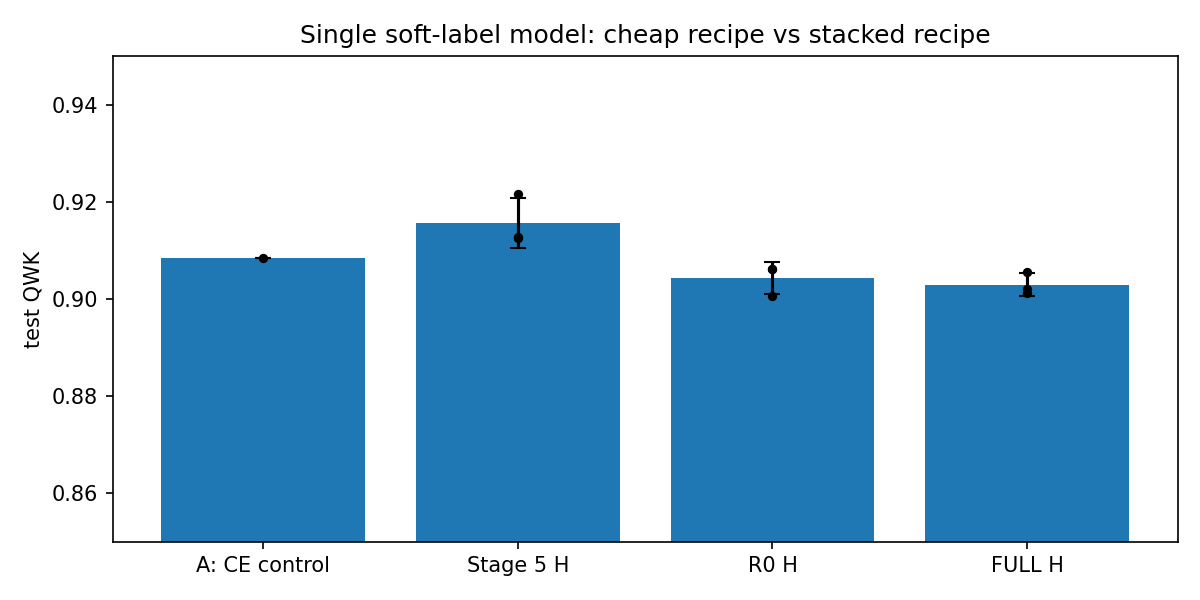

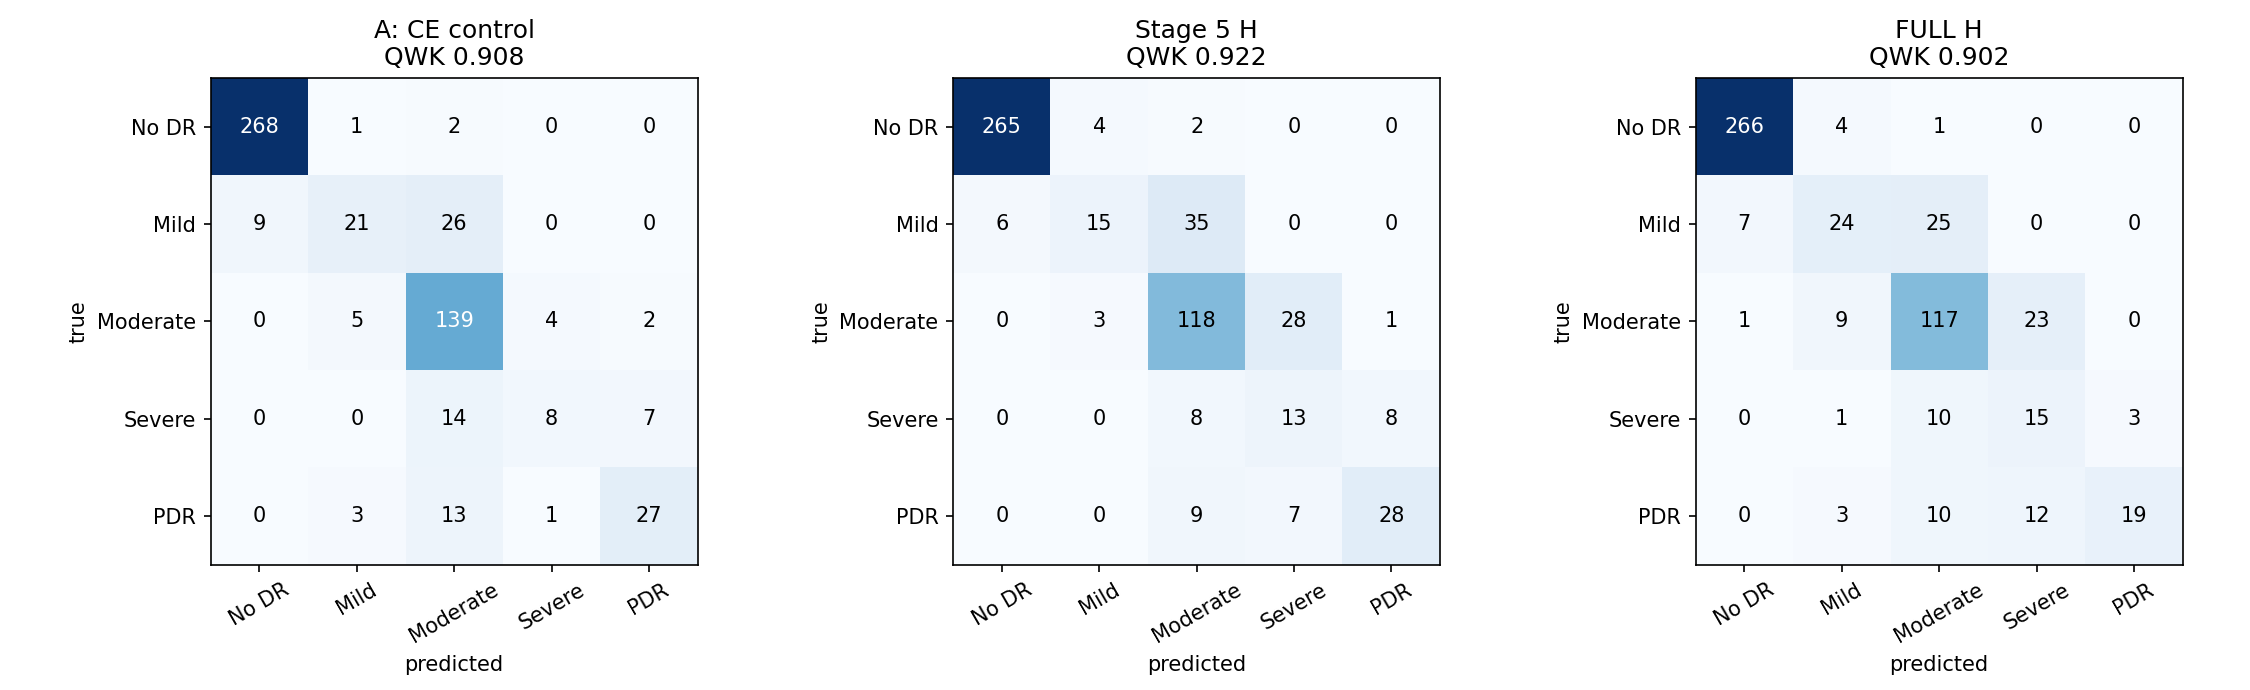

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
labels_plot = [("A: CE control", "A: CE control (Kaggle)", "A"), ("Stage 5 H", S5, "H"), ("R0 H", "R0", "H"), ("FULL H", "FULL", "H")]
vals = [head[(head.group == g) & (head.arm == a)]["qwk"] for _, g, a in labels_plot]
ax.bar(range(4), [v.mean() for v in vals], yerr=[v.std() if len(v) > 1 else 0 for v in vals], capsize=4)
for i, v in enumerate(vals):
    ax.scatter([i] * len(v), v, color="k", s=12, zorder=3)
ax.set_xticks(range(4)); ax.set_xticklabels([l for l, _, _ in labels_plot]); ax.set_ylim(0.85, 0.95); ax.set_ylabel("test QWK")
ax.set_title("Single soft-label model: cheap recipe vs stacked recipe"); fig.tight_layout(); fig.savefig(FIG_DIR / "qwk_by_recipe.png", dpi=150); plt.show()

panels = [("A: CE control", preds[("ce_s42_k", "A", "-")]), ("Stage 5 H", preds[(f"soft_s{s0}", "H", "-")]), ("FULL H", preds[(f"FULL_s{s0}", "H", "TTA")])]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, pred) in zip(axes, panels):
    cm = confusion_matrix(y_test, pred, labels=list(range(NUM_CLASSES)))
    ax.imshow(cm, cmap="Blues")
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=30); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_title(f"{title}\nQWK {qwk(y_test, pred):.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion_matrices.png", dpi=150); plt.show()

recall = lambda pred: pd.Series([(pred[y_test == c] == c).mean() for c in range(NUM_CLASSES)], index=CLASS_NAMES)
per_class = pd.DataFrame({t: recall(p) for t, p in panels}); per_class["test images"] = np.bincount(y_test, minlength=NUM_CLASSES)
per_class.to_csv(STAGE8_DIR / "per_class_recall.csv")
display(per_class.style.format(precision=3))

## 13. Files

Written to `dr-grading/stage8/` in this kernel's output: `results_per_run.csv`, `results_mean_over_seeds.csv`, `leave_one_out_seed42.csv`, `paired_bootstrap.csv`, `prediction_check.csv`, `per_class_recall.csv`, `figures/`, `runs/<name>/`. Copy the CSVs and figures into `experiments/10_stacked_recipe/results/` and write `experiments/10_stacked_recipe/results.md`.